<a href="https://colab.research.google.com/github/mahmoud-elmowafy/Diabetes-Prediction-Logistic-Regression/blob/main/Diabetes_Prediction_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [5]:
import pandas as pd

df = pd.read_csv('/kaggle/input/diabetes-prediction-dataset/diabetes_prediction_dataset.csv')

print("Dataset Shape:", df.shape)

display(df.head())

df.info()

Dataset Shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [6]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 3854


In [8]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


diabetes
0    91500
1     8500
Name: count, dtype: int64


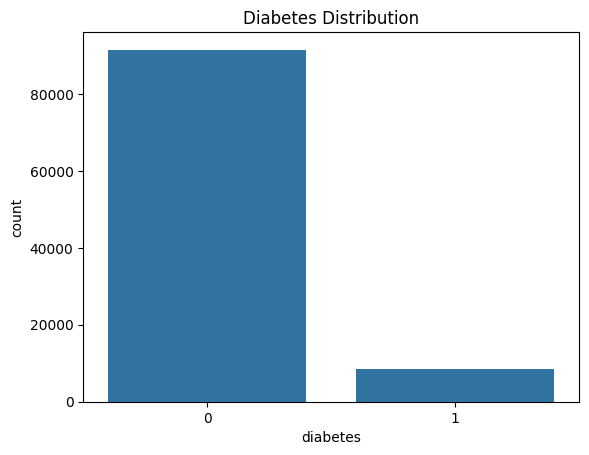

In [9]:
print(df['diabetes'].value_counts())

sns.countplot(data=df, x='diabetes')
plt.title('Diabetes Distribution')
plt.show()

In [10]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Duplicate Rows:
3854


In [11]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

print("Remaining Duplicates:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (96146, 9)
Remaining Duplicates: 0


In [12]:
print("Numerical Columns:")
print(df.select_dtypes(include=['int64', 'float64']).columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include=['object']).columns.tolist())

Numerical Columns:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Categorical Columns:
['gender', 'smoking_history']


In [13]:
# Separate Features and Target
X = df.drop('diabetes', axis=1)
y = df['diabetes']

# Identify Numerical and Categorical Features
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Numerical Features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical Features: ['gender', 'smoking_history']

Features Shape: (96146, 8)
Target Shape: (96146,)


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (76916, 8)
Testing Data: (19230, 8)

Training Target Distribution:
diabetes
0    0.911774
1    0.088226
Name: proportion, dtype: float64

Testing Target Distribution:
diabetes
0    0.911804
1    0.088196
Name: proportion, dtype: float64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical Transformer
numeric_transformer = StandardScaler()

# Categorical Transformer
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine Transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create Model Pipeline
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train Model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [17]:
# Predict Test Data
y_pred = model.predict(X_test)

# Predict Probabilities
y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions:")
print(y_pred[:20])

print("\nActual Values:")
print(y_test.values[:20])

Predictions:
[1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 1 0]

Actual Values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0]


Confusion Matrix:
[[15516  2018]
 [  204  1492]]


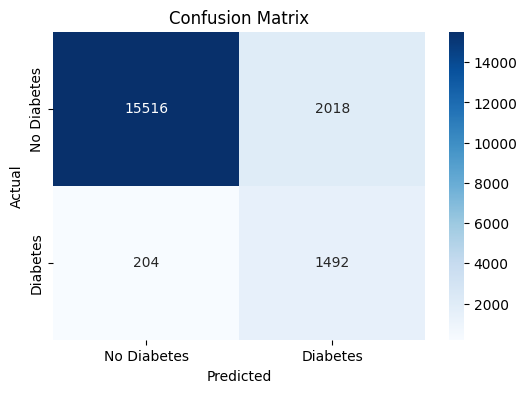

In [18]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Logistic Regression Evaluation")
print("--------------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Logistic Regression Evaluation
--------------------------------
Accuracy: 0.8845
Precision: 0.4251
Recall: 0.8797
F1 Score: 0.5732


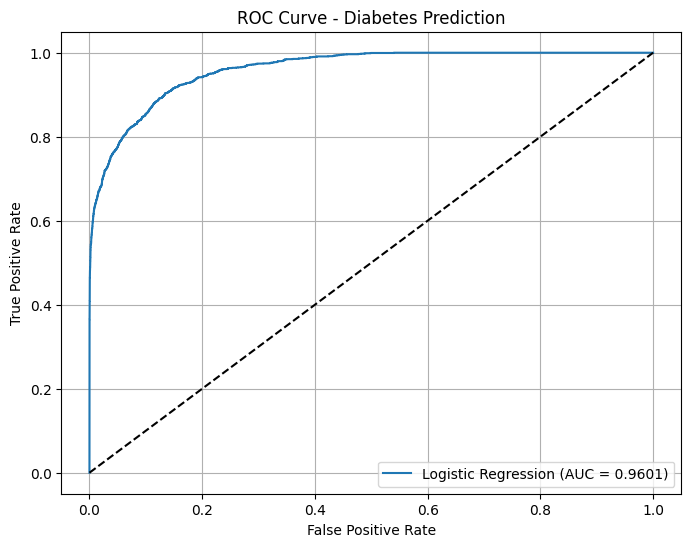

AUC Score: 0.9601


In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {auc:.4f})'
)

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Diabetes Prediction')

plt.legend()
plt.grid()
plt.show()

print("AUC Score:", round(auc, 4))

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Apply 5-Fold Cross Validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation Metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Cross Validation
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

# Display Results
print("5-Fold Cross Validation Results")
print("--------------------------------")

for metric in scoring:
    scores = cv_results[f'test_{metric}']

    print(f"{metric}: {scores.mean():.4f}")
    print(f"Standard Deviation: {scores.std():.4f}")
    print()

5-Fold Cross Validation Results
--------------------------------
accuracy: 0.8872
Standard Deviation: 0.0016

precision: 0.4320
Standard Deviation: 0.0032

recall: 0.8827
Standard Deviation: 0.0099

f1: 0.5800
Standard Deviation: 0.0018

roc_auc: 0.9622
Standard Deviation: 0.0018

